# 02: monitoring the training and diagnosing its failures (milestone m2)

Same data and same dense baseline as `01_dense_baseline.ipynb` (milestone m1). Here we follow Session 6 and TP06: we
plot the training and validation curves, read them, check that the training itself works, and measure what each tool
against overfitting changes.

## Imports

- `torch`, `torch.nn`: the networks; `DataLoader` and `TensorDataset` serve mini-batches from tensors.
- `torchvision.datasets`: `ImageFolder` reads the subset (one folder per genre).
- `copy`: `copy.deepcopy` makes an independent copy of the weights (for early stopping).
- `pandas`: reads `metadata.csv` (the artist of each image) and holds the comparison table.
- `numpy`, `matplotlib`: arrays and training curves.

In [1]:
import os
import copy
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets

DATA_DIR = "data/wikiart_genre5"
np.random.seed(0)
torch.manual_seed(0)
torch.set_num_threads(2)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

device: cpu


## Helper functions

The training tools of TP06:

- `train_one_epoch(model, loader, loss_fn, optimizer)`: one pass over the training data with the 5 lines of the
  training loop; returns the mean training loss.
- `evaluate(model, loader, loss_fn)`: returns `(mean loss, accuracy)` in evaluation mode, without gradients.
- `fit(model, optimizer, n_epochs, ...)`: trains for `n_epochs` and returns a **history**, a dictionary of lists with
  one value per epoch: `"train_loss"`, `"train_acc"`, `"val_loss"`, `"val_acc"`, `"lr"`. The train metrics are
  measured in evaluation mode on the whole training set after each epoch (`record`), so that train and validation
  are measured the same way.
- `plot_history(history)` and `plot_compare(histories, key)`: the curves.

In [2]:
def train_one_epoch(model, loader, loss_fn, optimizer):
    model.train()
    total, n = 0.0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        loss = loss_fn(model(xb), yb)
        loss.backward()
        optimizer.step()
        total += loss.item() * len(yb)
        n += len(yb)
    return total / n


def evaluate(model, loader, loss_fn):
    model.eval()
    total, correct, n = 0.0, 0, 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            total += loss_fn(out, yb).item() * len(yb)
            correct += (out.argmax(dim=1) == yb).sum().item()
            n += len(yb)
    return total / n, correct / n


def new_history():
    return {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": [], "lr": []}


def record(history, model, optimizer):
    """Measure the model on the training and validation sets and append the results to the history."""
    tl, ta = evaluate(model, train_eval_loader, loss_fn)
    vl, va = evaluate(model, val_loader, loss_fn)
    history["train_loss"].append(tl); history["train_acc"].append(ta)
    history["val_loss"].append(vl); history["val_acc"].append(va)
    history["lr"].append(optimizer.param_groups[0]["lr"])


def fit(model, optimizer, n_epochs, train_epoch_fn=train_one_epoch, scheduler=None, verbose=False):
    torch.manual_seed(1)                       # same order of the mini-batches for every run
    history = new_history()
    for epoch in range(n_epochs):
        train_epoch_fn(model, train_loader, loss_fn, optimizer)
        record(history, model, optimizer)
        if scheduler is not None:
            scheduler.step()
        if verbose:
            print(f"epoch {epoch + 1:2d}  train loss {history['train_loss'][-1]:.3f}  "
                  f"val loss {history['val_loss'][-1]:.3f}  val acc {history['val_acc'][-1]:.3f}")
    return history


def plot_history(history, title=""):
    e = range(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    axes[0].plot(e, history["train_loss"], label="train"); axes[0].plot(e, history["val_loss"], label="validation")
    axes[0].set_xlabel("epoch"); axes[0].set_ylabel("loss"); axes[0].legend()
    axes[1].plot(e, history["train_acc"], label="train"); axes[1].plot(e, history["val_acc"], label="validation")
    axes[1].set_xlabel("epoch"); axes[1].set_ylabel("accuracy"); axes[1].legend()
    fig.suptitle(title)
    plt.show()


def plot_compare(histories, key="val_loss"):
    plt.figure(figsize=(7, 3.5))
    for name, h in histories.items():
        plt.plot(range(1, len(h[key]) + 1), h[key], label=name)
    plt.xlabel("epoch"); plt.ylabel(key); plt.legend()
    plt.show()


def count_parameters(model):
    return sum(p.numel() for p in model.parameters())

## The data, exactly as in notebook 01

Same loading, same split by artist (seed 0: 1 000 / 250 / 250 images, 200 / 50 / 50 per genre, no named artist in
two sets), same standardisation with the training statistics only. The test set is not used in this notebook: it
was measured once, at the end of milestone m1.

In [3]:
folder = datasets.ImageFolder(DATA_DIR)
CLASSES = folder.classes
images = np.stack([np.array(img) for img, _ in folder])          # (N, 128, 128, 3), uint8, values 0 to 255
X_full = torch.tensor(images).permute(0, 3, 1, 2).float() / 255  # (N, 3, 128, 128), pixels in [0, 1]
y_full = torch.tensor(folder.targets)                             # (N,), int64

print("X_full", tuple(X_full.shape), X_full.dtype, "| y_full", tuple(y_full.shape), y_full.dtype)
print("images per class:", dict(zip(CLASSES, torch.bincount(y_full).tolist())))

X_full (1500, 3, 128, 128) torch.float32 | y_full (1500,) torch.int64
images per class: {'cityscape': 300, 'landscape': 300, 'portrait': 300, 'religious_painting': 300, 'still_life': 300}


In [4]:
meta = pd.read_csv(os.path.join(DATA_DIR, "metadata.csv")).set_index("path")
artist = [meta.loc[os.path.relpath(p, DATA_DIR), "artist"] for p, _ in folder.samples]
# one group per named artist; "Unknown Artist" is a catch-all of many painters, so each of its images is its own group
group = [a if a != "Unknown Artist" else f"unknown_{i}" for i, a in enumerate(artist)]
names = sorted(set(group))
members = {g: [i for i, h in enumerate(group) if h == g] for g in names}

# groups in a random order: a group goes to test if it fits there (at most 1/6 of each class), else to validation,
# else to train. Classes stay balanced and an artist never appears in two sets.
order = torch.randperm(len(names), generator=torch.Generator().manual_seed(0)).tolist()
per_class = torch.bincount(y_full) // 6                         # 50 images of each class in test and in validation
filled = {"test": torch.zeros(len(CLASSES), dtype=torch.int64), "val": torch.zeros(len(CLASSES), dtype=torch.int64)}
split = {"train": [], "val": [], "test": []}
for k in order:
    idx = members[names[k]]
    counts = torch.bincount(y_full[idx], minlength=len(CLASSES))
    s = next((s for s in ["test", "val"] if (filled[s] + counts <= per_class).all()), "train")
    if s != "train":
        filled[s] += counts
    split[s] += idx
train_idx, val_idx, test_idx = (torch.tensor(sorted(split[s])) for s in ["train", "val", "test"])

X_train_raw, y_train = X_full[train_idx], y_full[train_idx]
X_val_raw, y_val = X_full[val_idx], y_full[val_idx]
X_test_raw, y_test = X_full[test_idx], y_full[test_idx]

named = {s: {artist[i] for i in split[s]} - {"Unknown Artist"} for s in split}
assert not (named["train"] & named["val"] or named["train"] & named["test"] or named["val"] & named["test"]), "an artist is on both sides"
print(f"train {len(train_idx)}, val {len(val_idx)}, test {len(test_idx)} | no named artist in two sets")
for s, y in [("train", y_train), ("val", y_val), ("test", y_test)]:
    print(f"{s:5s}", dict(zip(CLASSES, torch.bincount(y, minlength=len(CLASSES)).tolist())))

train 1000, val 250, test 250 | no named artist in two sets
train {'cityscape': 200, 'landscape': 200, 'portrait': 200, 'religious_painting': 200, 'still_life': 200}
val   {'cityscape': 50, 'landscape': 50, 'portrait': 50, 'religious_painting': 50, 'still_life': 50}
test  {'cityscape': 50, 'landscape': 50, 'portrait': 50, 'religious_painting': 50, 'still_life': 50}


Standardisation and loaders, as in TP06: `train_loader` serves shuffled mini-batches of 64 for training;
`train_eval_loader` measures the whole training set (in evaluation mode, after each epoch); `val_loader` the
validation set.

In [5]:
mean = X_train_raw.mean().item()   # one number over all the training pixels
std = X_train_raw.std().item()
X_train = (X_train_raw - mean) / std
X_val = (X_val_raw - mean) / std

BATCH_SIZE = 64
train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True)
train_eval_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=1000)
val_loader = DataLoader(TensorDataset(X_val, y_val), batch_size=1000)
loss_fn = nn.CrossEntropyLoss()
print(f"mean {mean:.4f}, std {std:.4f} | train {tuple(X_train.shape)}, validation {tuple(X_val.shape)}")

mean 0.4546, std 0.2533 | train (1000, 3, 128, 128), validation (250, 3, 128, 128)


## The training curves of the baseline

Same network and same recipe as milestone m1 (49 152 → 128 sigmoid → 5, plain SGD with a learning rate of 0.2), but
trained for 30 epochs instead of 10, as in TP06, to see where the curves go. `make_baseline()` builds a fresh network
each time we need one. After each epoch, `fit` measures the loss and the accuracy on the whole training set and on the
validation set: course 6, *"always plot both"*.

epoch  1  train loss 1.387  val loss 1.518  val acc 0.372
epoch  2  train loss 1.307  val loss 1.502  val acc 0.316


epoch  3  train loss 1.262  val loss 1.508  val acc 0.344
epoch  4  train loss 1.060  val loss 1.413  val acc 0.420


epoch  5  train loss 1.122  val loss 1.524  val acc 0.368
epoch  6  train loss 0.960  val loss 1.523  val acc 0.384


epoch  7  train loss 0.848  val loss 1.489  val acc 0.404
epoch  8  train loss 0.785  val loss 1.478  val acc 0.400


epoch  9  train loss 0.942  val loss 1.807  val acc 0.348
epoch 10  train loss 0.648  val loss 1.538  val acc 0.412


epoch 11  train loss 0.926  val loss 1.864  val acc 0.388
epoch 12  train loss 0.604  val loss 1.532  val acc 0.408


... (5 outputs left out)

epoch 23  train loss 0.411  val loss 1.841  val acc 0.372
epoch 24  train loss 0.333  val loss 1.776  val acc 0.416


epoch 25  train loss 0.433  val loss 1.773  val acc 0.404
epoch 26  train loss 0.419  val loss 1.760  val acc 0.396


epoch 27  train loss 0.398  val loss 1.812  val acc 0.400
epoch 28  train loss 0.297  val loss 1.795  val acc 0.388


epoch 29  train loss 0.351  val loss 1.865  val acc 0.372
epoch 30  train loss 0.268  val loss 1.731  val acc 0.432


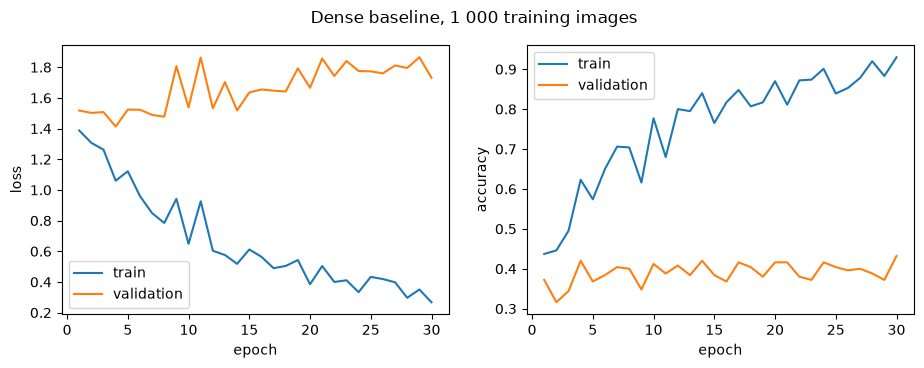

In [6]:
N_IN = 3 * 128 * 128
EPOCHS = 30
LR = 0.2


def make_baseline():
    return nn.Sequential(
        nn.Flatten(),
        nn.Linear(N_IN, 128),
        nn.Sigmoid(),
        nn.Linear(128, len(CLASSES)),
    ).to(device)


torch.manual_seed(0)
model_base = make_baseline()
optimizer = torch.optim.SGD(model_base.parameters(), lr=LR)
history_base = fit(model_base, optimizer, EPOCHS, verbose=True)
plot_history(history_base, "Dense baseline, 1 000 training images")

## Measure the overfitting

As in TP06 (Exercise 3), two numbers from `history_base`:

- `gap_base`: final train accuracy minus final validation accuracy. A large gap means the network does much better on
  the images it trained on than on new ones.
- `best_epoch_base`: the epoch (counted from 1) where the validation loss is the smallest. Everything after it is
  wasted, even harmful, training.

In [7]:
gap_base = history_base["train_acc"][-1] - history_base["val_acc"][-1]
best_epoch_base = int(np.argmin(history_base["val_loss"])) + 1

print(f"final train accuracy {history_base['train_acc'][-1]:.3f} | final validation accuracy {history_base['val_acc'][-1]:.3f} "
      f"| gap {gap_base:.3f}")
print(f"best validation loss {min(history_base['val_loss']):.3f} at epoch {best_epoch_base} of {EPOCHS} "
      f"| final validation loss {history_base['val_loss'][-1]:.3f}")
print(f"start: train loss {history_base['train_loss'][0]:.3f} -> end: {history_base['train_loss'][-1]:.3f}")

final train accuracy 0.930 | final validation accuracy 0.432 | gap 0.498
best validation loss 1.413 at epoch 4 of 30 | final validation loss 1.731
start: train loss 1.387 -> end: 0.268


**What we see.** The curves show **overfitting** (Session 6). The training accuracy climbs to 0.93 while the validation
accuracy stays around 0.40 (between 0.32 and 0.43 over the 30 epochs): a gap of 0.50. The validation loss is the
best at epoch 4 (1.413), then rises to 1.73: the network becomes over-confident on paintings it has never seen. With
6.3 million parameters for 1 000 training images, it memorises its training set instead of learning the genres.

A second symptom: the training loss zigzags (it goes back up at epochs 5, 9, 11, 15, 19, 21...). Plain SGD with a learning
rate of 0.2 takes steps that are too large to settle: the "loss very noisy, does not settle" row of the diagnosis
table of Session 6.

## Early stopping: keep the best validation epoch

The tool of Session 6 that follows directly from the curves: after each epoch, if the validation loss is the best so
far, save a copy of the weights (`copy.deepcopy(model.state_dict())`: without the deep copy, the "copy" would keep
following the training). If it has not improved for `patience` epochs, stop. At the end, reload the best weights.
Same network, same initial weights, same recipe as above: only the stopping rule changes (TP06, Exercise 10).

In [8]:
def fit_early_stopping(model, optimizer, max_epochs, patience):
    torch.manual_seed(1)
    history = new_history()
    best_loss, best_state, best_epoch, wait = float("inf"), None, 0, 0
    for epoch in range(1, max_epochs + 1):
        train_one_epoch(model, train_loader, loss_fn, optimizer)
        record(history, model, optimizer)
        val_loss = history["val_loss"][-1]
        if val_loss < best_loss:                                     # improvement: save a checkpoint
            best_loss, best_epoch, wait = val_loss, epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            wait += 1
            if wait >= patience:                                     # no improvement for `patience` epochs
                break
    model.load_state_dict(best_state)                                # go back to the best epoch
    return history, best_epoch


torch.manual_seed(0)
model_es = make_baseline()
optimizer = torch.optim.SGD(model_es.parameters(), lr=LR)
history_es, best_epoch_es = fit_early_stopping(model_es, optimizer, max_epochs=EPOCHS, patience=5)

train_loss_es, train_acc_es = evaluate(model_es, train_eval_loader, loss_fn)
val_loss_es, val_acc_es = evaluate(model_es, val_loader, loss_fn)
print(f"stopped after {len(history_es['val_loss'])} epochs, best epoch {best_epoch_es}")
print(f"{'':16s} {'train acc':>9s} {'val acc':>8s} {'gap':>6s} {'val loss':>9s}")
print(f"{'baseline (30)':16s} {history_base['train_acc'][-1]:9.3f} {history_base['val_acc'][-1]:8.3f} {gap_base:6.3f} {history_base['val_loss'][-1]:9.3f}")
print(f"{'early stopping':16s} {train_acc_es:9.3f} {val_acc_es:8.3f} {train_acc_es - val_acc_es:6.3f} {val_loss_es:9.3f}")

stopped after 9 epochs, best epoch 4
                 train acc  val acc    gap  val loss
baseline (30)        0.930    0.432  0.498     1.731
early stopping       0.623    0.420  0.203     1.413


**What we see.** Early stopping stops after 9 epochs and keeps epoch 4. The validation loss of the kept model is 1.413
instead of 1.731, and the gap between train and validation falls from 0.50 to 0.20: the overfitting diagnosis is
confirmed, and 21 of the 30 epochs were wasted. But the validation accuracy does not improve (0.420 versus 0.432):
stopping earlier avoids memorising, it does not teach the network to recognise the genres better. As in TP06, no
tool works miracles on 1 000 images; the limit is the dense network itself (milestone m3).

## Failure diagnosis

We read the runs above with the diagnosis table of Session 6: for each symptom, the evidence in our numbers, the
likely cause, and what we did.

| Symptom | Evidence | Likely cause | What we did |
|---|---|---|---|
| Train loss goes down, validation loss goes up | Train accuracy 0.93, validation 0.43 after 30 epochs (gap 0.50). Validation loss best at epoch 4 (1.413), 1.731 at epoch 30 | **Overfitting**: 6.3 million parameters for 1 000 training images, the network memorises them | **Early stopping** (patience 5): keeps epoch 4, gap 0.20, validation loss 1.413. Not tried: weight decay, dropout; the first fix is always more data |
| Loss very noisy, does not settle | The training loss goes back up at epochs 5, 9, 11, 15, 19, 21... (0.648 then 0.926 at epoch 11) | Learning rate 0.2 too large for plain SGD, batches of 64 | Not changed here. Fixes of the course: a learning-rate schedule (decay), a larger batch |
| Loss becomes huge, then `nan` | Never: every loss stays finite | | Ruled out |
| Loss flat from the start, at ln 5 = 1.61 | No: the training loss is 1.387 after one epoch and 0.268 after 30 | | Ruled out: the training loop works and the network learns |

**What remains.** Whatever the stopping rule, the validation accuracy stays around 0.40 (twice the chance level of
0.20, and 0.380 on the test set in milestone m1). This is not a bug of the training: it is the limit of the model. A
dense network flattens the image into 49 152 independent numbers and ignores which pixels are neighbours (Sessions 5
and 7), and 1 000 images are far too few to learn 6.3 million parameters. The confusion matrix of m1 points the same
way: outdoor scenes (landscape and cityscape) are mixed up and religious paintings are almost never recognised. The
next step is a network that knows the structure of images and has already learned from 1.2 million photos: a
pretrained ResNet (milestone m3).